In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# project folder
!mkdir -p /content/drive/MyDrive/tomato_project


Mounted at /content/drive


In [ ]:
!pip install -q kaggle


In [ ]:
from google.colab import files
files.upload()


Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"ojaswinithote","key":"482c2bcfeeaa45d9f755a1d289e201dd"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
!kaggle datasets download -d luisolazo/tomato-diseases


Dataset URL: https://www.kaggle.com/datasets/luisolazo/tomato-diseases
License(s): CC0-1.0
100% 411M/411M [00:32<00:00, 13.4MB/s]



In [ ]:
!unzip -q tomato-diseases.zip
!ls


drive  kaggle.json  sample_data  test  tomato-diseases.zip  train


In [ ]:
dataset_path = "/content/train"


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam


In [ ]:
img_size = (224,224)
batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=30,
    zoom_range=0.3,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)


In [ ]:
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

val_generator = val_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

num_classes = train_generator.num_classes
print(train_generator.class_indices)


Found 14206 images belonging to 10 classes.
Found 3547 images belonging to 10 classes.
{'bacterial_spot': 0, 'early_blight': 1, 'healthy': 2, 'late_blight': 3, 'leaf_mold': 4, 'mosaic_virus': 5, 'septoria_leaf_spot': 6, 'target_spot': 7, 'twospotted_spider_mite': 8, 'yellow_leaf_curl_virus': 9}


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = train_generator.classes

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(classes),
    y=classes
)

class_weights = dict(enumerate(class_weights))
print(class_weights)


{0: np.float64(1.0569940476190476), 1: np.float64(0.8154994259471872), 2: np.float64(0.9426675514266755), 3: np.float64(0.8481194029850746), 4: np.float64(1.2162671232876712), 5: np.float64(1.4828810020876826), 6: np.float64(1.3376647834274953), 7: np.float64(1.5997747747747748), 8: np.float64(1.4407707910750507), 9: np.float64(0.4939499304589708)}


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/tomato_project/tomato_model.keras"

if os.path.exists(MODEL_PATH):
    model = load_model(MODEL_PATH)
    print("Model loaded")
else:
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))

    for layer in base_model.layers:
        layer.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.5)(x)
    preds = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=preds)

    model.compile(Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])


Model loaded


In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights
)

model.save(MODEL_PATH)


Epoch 1/10
444/444 ━━━━━━━━━━━━━━━━━━━━ 282s 554ms/step - accuracy: 0.9851 - loss: 0.0426 - val_accuracy: 0.9662 - val_loss: 0.0944
Epoch 2/10
444/444 ━━━━━━━━━━━━━━━━━━━━ 205s 461ms/step - accuracy: 0.9845 - loss: 0.0456 - val_accuracy: 0.9681 - val_loss: 0.0909
Epoch 3/10
444/444 ━━━━━━━━━━━━━━━━━━━━ 204s 458ms/step - accuracy: 0.9855 - loss: 0.0439 - val_accuracy: 0.9687 - val_loss: 0.0921
Epoch 4/10
444/444 ━━━━━━━━━━━━━━━━━━━━ 202s 454ms/step - accuracy: 0.9866 - loss: 0.0391 - val_accuracy: 0.9667 - val_loss: 0.0982
Epoch 5/10
444/444 ━━━━━━━━━━━━━━━━━━━━ 204s 459ms/step - accuracy: 0.9851 - loss: 0.0422 - val_accuracy: 0.9698 - val_loss: 0.0887
Epoch 6/10
444/444 ━━━━━━━━━━━━━━━━━━━━ 206s 464ms/step - accuracy: 0.9867 - loss: 0.0414 - val_accuracy: 0.9667 - val_loss: 0.0933
Epoch 7/10
444/444 ━━━━━━━━━━━━━━━━━━━━ 261s 461ms/step - accuracy: 0.9874 - loss: 0.0382 - val_accuracy: 0.9687 - val_loss: 0.0918
Epoch 8/10
444/444 ━━━━━━━━━━━━━━━━━━━━ 205s 462ms/step - accuracy: 0.9852 -

In [ ]:
for layer in model.layers[-80:]:
    layer.trainable = True

model.compile(Adam(5e-6), loss='categorical_crossentropy', metrics=['accuracy'])

history_ft = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5,
    class_weight=class_weights
)

model.save(MODEL_PATH)

Epoch 1/5
444/444 ━━━━━━━━━━━━━━━━━━━━ 250s 500ms/step - accuracy: 0.9873 - loss: 0.0411 - val_accuracy: 0.9698 - val_loss: 0.0884
Epoch 2/5
444/444 ━━━━━━━━━━━━━━━━━━━━ 202s 454ms/step - accuracy: 0.9885 - loss: 0.0348 - val_accuracy: 0.9712 - val_loss: 0.0847
Epoch 3/5
444/444 ━━━━━━━━━━━━━━━━━━━━ 203s 458ms/step - accuracy: 0.9873 - loss: 0.0381 - val_accuracy: 0.9724 - val_loss: 0.0817
Epoch 4/5
444/444 ━━━━━━━━━━━━━━━━━━━━ 202s 455ms/step - accuracy: 0.9885 - loss: 0.0341 - val_accuracy: 0.9701 - val_loss: 0.0871
Epoch 5/5
444/444 ━━━━━━━━━━━━━━━━━━━━ 203s 457ms/step - accuracy: 0.9881 - loss: 0.0364 - val_accuracy: 0.9712 - val_loss: 0.0882


In [ ]:
val_generator_eval = val_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 3547 images belonging to 10 classes.


In [ ]:
val_generator_eval.reset()

pred_probs = model.predict(val_generator_eval)
y_pred = np.argmax(pred_probs, axis=1)
y_true = val_generator_eval.classes
class_names = list(val_generator_eval.class_indices.keys())

111/111 ━━━━━━━━━━━━━━━━━━━━ 15s 95ms/step


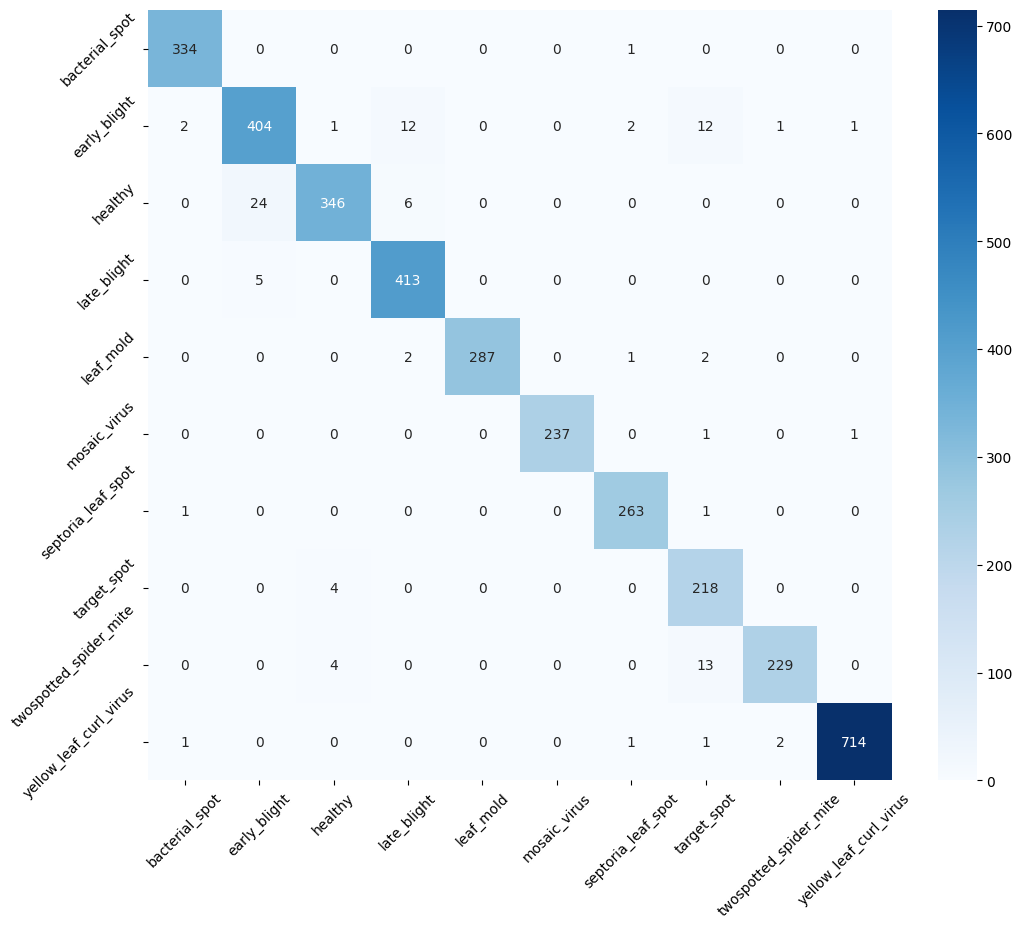

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.show()

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=class_names))

                        precision    recall  f1-score   support

        bacterial_spot       0.99      1.00      0.99       335
          early_blight       0.93      0.93      0.93       435
               healthy       0.97      0.92      0.95       376
           late_blight       0.95      0.99      0.97       418
             leaf_mold       1.00      0.98      0.99       292
          mosaic_virus       1.00      0.99      1.00       239
    septoria_leaf_spot       0.98      0.99      0.99       265
           target_spot       0.88      0.98      0.93       222
twospotted_spider_mite       0.99      0.93      0.96       246
yellow_leaf_curl_virus       1.00      0.99      1.00       719

              accuracy                           0.97      3547
             macro avg       0.97      0.97      0.97      3547
          weighted avg       0.97      0.97      0.97      3547



In [ ]:
from sklearn.metrics import accuracy_score

acc = accuracy_score(y_true, y_pred)
print("Overall Accuracy:", acc)

Overall Accuracy: 0.971243304200733


In [ ]:
print("Accuracy: {:.2f}%".format(acc*100))

Accuracy: 97.12%


In [ ]:
from tensorflow.keras.models import load_model

MODEL_PATH = "/content/drive/MyDrive/tomato_project/tomato_model.keras"
model = load_model(MODEL_PATH)

print("Model loaded successfully")

Model loaded successfully


In [ ]:
class_names = [
'bacterial_spot',
'early_blight',
'healthy',
'late_blight',
'leaf_mold',
'mosaic_virus',
'septoria_leaf_spot',
'target_spot',
'twospotted_spider_mite',
'yellow_leaf_curl_virus'
]

print("Class names loaded")

Class names loaded


Saving 0286577f-36c8-4b0d-bbf5-404993cd089d___Matt.S_CG 1422.JPG to 0286577f-36c8-4b0d-bbf5-404993cd089d___Matt.S_CG 1422.JPG
1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step
Top 3 predictions:
septoria_leaf_spot : 99.90%
target_spot : 0.10%
early_blight : 0.00%

Final Prediction: septoria_leaf_spot
Confidence: 99.90%


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

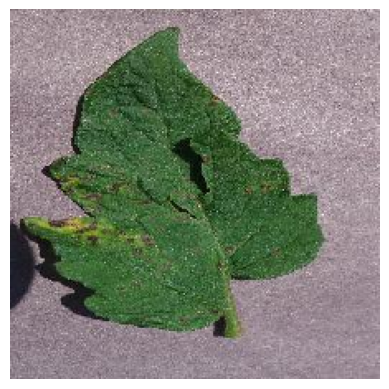

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# Upload image
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Load and preprocess image
img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
pred_probs = model.predict(img_array)

# Get predicted class
pred_class = np.argmax(pred_probs)

# Top-3 predictions
top3 = np.argsort(pred_probs[0])[-3:][::-1]

print("Top 3 predictions:")
for i in top3:
    print(f"{class_names[i]} : {pred_probs[0][i]*100:.2f}%")

print("\nFinal Prediction:", class_names[pred_class])
print(f"Confidence: {np.max(pred_probs)*100:.2f}%")

# Show image
plt.imshow(img)
plt.axis("off")

In [ ]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Function to generate Grad-CAM heatmap
def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        loss = predictions[:, pred_index]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = np.maximum(heatmap, 0) / np.max(heatmap)
    return heatmap

In [ ]:
def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)

        # Fix for list output
        if isinstance(predictions, list):
            predictions = predictions[0]

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
            pred_index = int(pred_index)

        loss = predictions[:, pred_index]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = np.maximum(heatmap, 0) / np.max(heatmap)
    return heatmap

In [ ]:
for layer in model.layers:
    print(layer.name)

input_layer
Conv1
bn_Conv1
Conv1_relu
expanded_conv_depthwise
expanded_conv_depthwise_BN
expanded_conv_depthwise_relu
expanded_conv_project
expanded_conv_project_BN
block_1_expand
block_1_expand_BN
block_1_expand_relu
block_1_pad
block_1_depthwise
block_1_depthwise_BN
block_1_depthwise_relu
block_1_project
block_1_project_BN
block_2_expand
block_2_expand_BN
block_2_expand_relu
block_2_depthwise
block_2_depthwise_BN
block_2_depthwise_relu
block_2_project
block_2_project_BN
block_2_add
block_3_expand
block_3_expand_BN
block_3_expand_relu
block_3_pad
block_3_depthwise
block_3_depthwise_BN
block_3_depthwise_relu
block_3_project
block_3_project_BN
block_4_expand
block_4_expand_BN
block_4_expand_relu
block_4_depthwise
block_4_depthwise_BN
block_4_depthwise_relu
block_4_project
block_4_project_BN
block_4_add
block_5_expand
block_5_expand_BN
block_5_expand_relu
block_5_depthwise
block_5_depthwise_BN
block_5_depthwise_relu
block_5_project
block_5_project_BN
block_5_add
block_6_expand
block_6_ex

In [ ]:
last_conv_layer_name = "Conv_1"

In [ ]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Grad-CAM function
def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)

        if isinstance(predictions, list):
            predictions = predictions[0]

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
            pred_index = int(pred_index)

        loss = predictions[:, pred_index]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = np.maximum(heatmap, 0) / np.max(heatmap)
    return heatmap


# Display function
def display_gradcam(img_path, model, last_conv_layer_name):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    heatmap = get_gradcam_heatmap(model, img_array, last_conv_layer_name)

    img_cv = cv2.imread(img_path)
    img_cv = cv2.resize(img_cv, (224,224))

    heatmap = cv2.resize(heatmap, (224,224))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    superimposed_img = heatmap * 0.4 + img_cv

    plt.figure(figsize=(6,6))
    plt.imshow(cv2.cvtColor(superimposed_img.astype('uint8'), cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title("Grad-CAM")
    plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


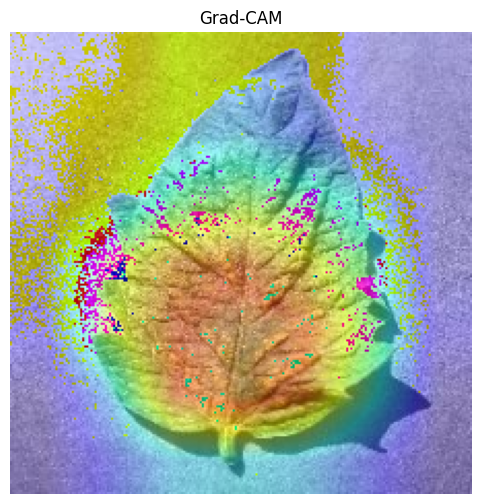

In [ ]:
display_gradcam(img_path, model, last_conv_layer_name)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving 01854aac-d409-4136-b885-3df6943cc349___Com.G_SpM_FL 1374.JPG to 01854aac-d409-4136-b885-3df6943cc349___Com.G_SpM_FL 1374.JPG


In [ ]:
img_path = list(uploaded.keys())[0]
print(img_path)

01854aac-d409-4136-b885-3df6943cc349___Com.G_SpM_FL 1374.JPG


In [ ]:
display_gradcam(img_path, model, last_conv_layer_name)

NameError: name 'display_gradcam' is not defined

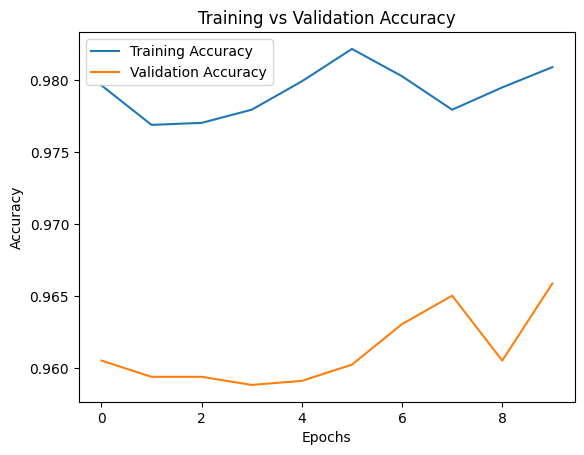

In [ ]:
import matplotlib.pyplot as plt

plt.figure()

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

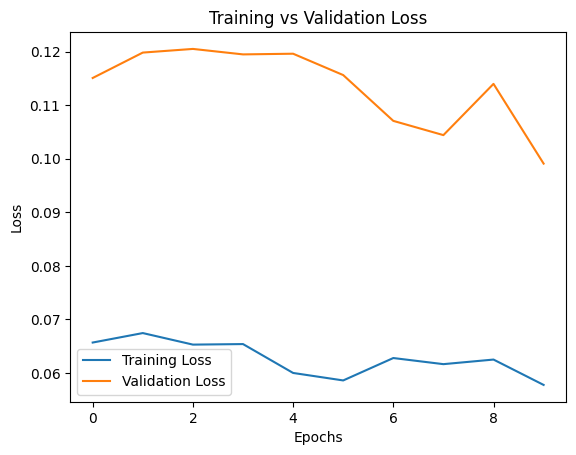

In [ ]:
plt.figure()

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()

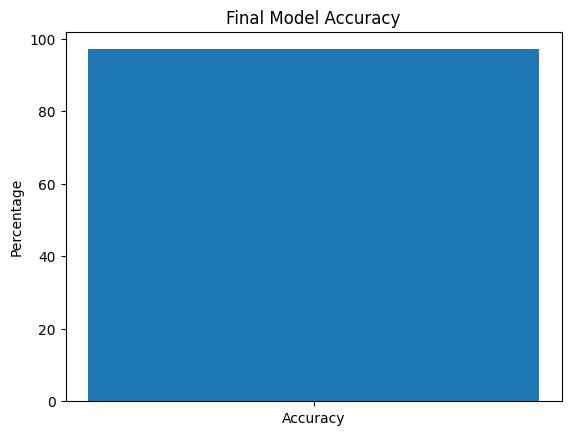

In [ ]:
import matplotlib.pyplot as plt

labels = ['Accuracy']
values = [acc * 100]

plt.bar(labels, values)
plt.title("Final Model Accuracy")
plt.ylabel("Percentage")

plt.show()

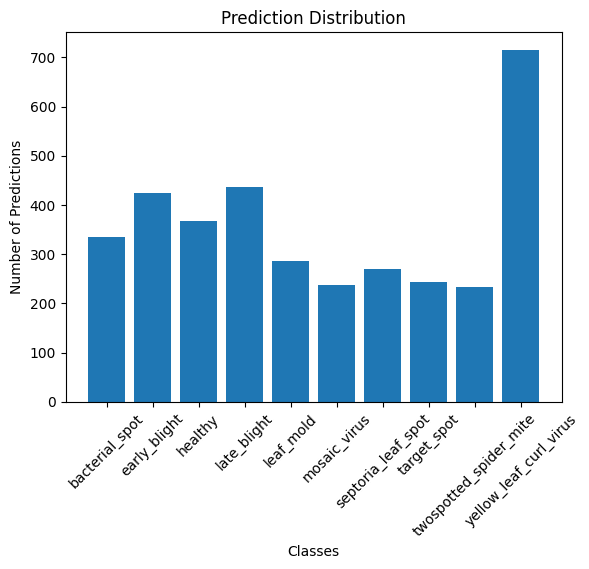

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

unique, counts = np.unique(y_pred, return_counts=True)

plt.bar([class_names[i] for i in unique], counts)
plt.title("Prediction Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Predictions")
plt.xticks(rotation=45)

plt.show()

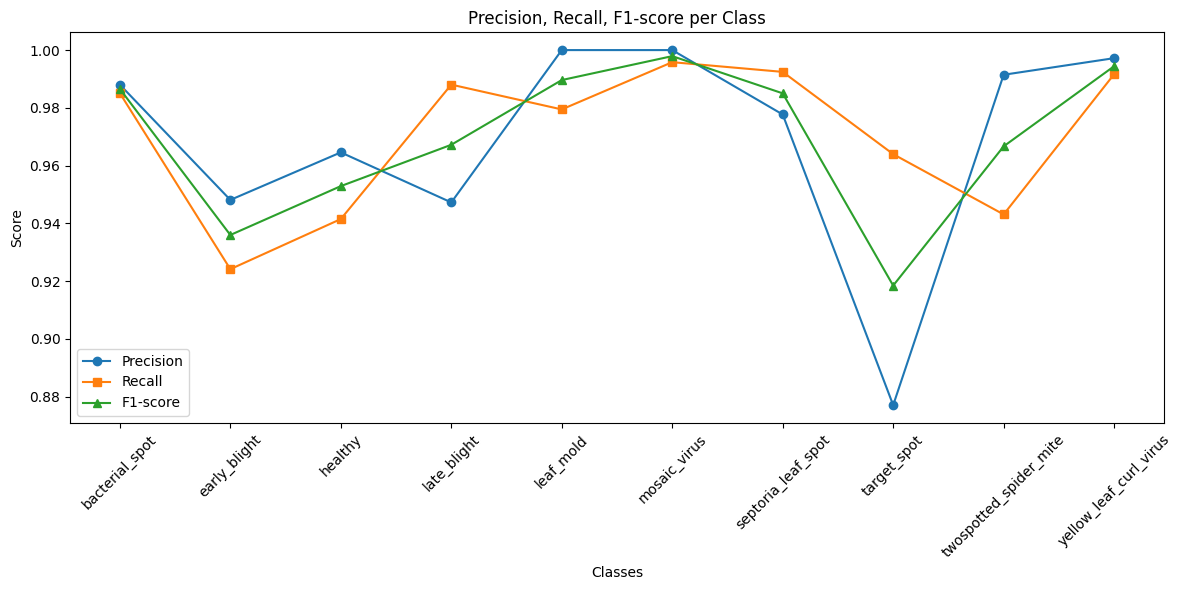

In [ ]:
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import numpy as np

# Generate classification report as dictionary
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

# Extract metrics
classes = list(report.keys())[:-3]  # remove avg/total rows
precision = [report[c]['precision'] for c in classes]
recall = [report[c]['recall'] for c in classes]
f1 = [report[c]['f1-score'] for c in classes]

x = np.arange(len(classes))

# Plot
plt.figure(figsize=(12,6))

plt.plot(x, precision, marker='o', label='Precision')
plt.plot(x, recall, marker='s', label='Recall')
plt.plot(x, f1, marker='^', label='F1-score')

plt.xticks(x, classes, rotation=45)
plt.title("Precision, Recall, F1-score per Class")
plt.xlabel("Classes")
plt.ylabel("Score")
plt.legend()

plt.tight_layout()
plt.show()

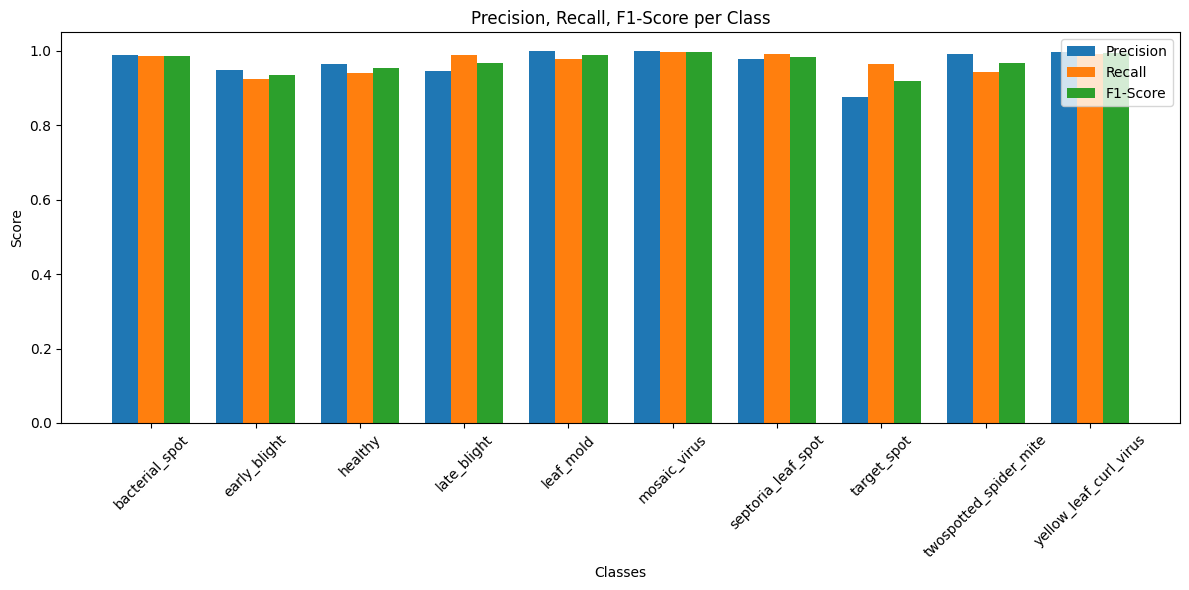

In [ ]:
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import numpy as np

# Generate report
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

# Extract class labels (remove avg rows)
classes = [c for c in report.keys() if c not in ('accuracy', 'macro avg', 'weighted avg')]

precision = [report[c]['precision'] for c in classes]
recall = [report[c]['recall'] for c in classes]
f1_score = [report[c]['f1-score'] for c in classes]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(12,6))

# Bar graph (better for presentation)
plt.bar(x - width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x + width, f1_score, width, label='F1-Score')

plt.xticks(x, classes, rotation=45)
plt.xlabel("Classes")
plt.ylabel("Score")
plt.title("Precision, Recall, F1-Score per Class")
plt.legend()

plt.tight_layout()
plt.show()